In [1]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cmocean
import numpy as np

import utils
import definitions

# Maps

Target: Figure 12 in [Narsey et al (2025)](https://connectsci.au/es/article/75/3/ES25015/252075/Disentangling-the-uncertainties-in-regional).

### CroppingFS

In [2]:
cropping_region = definitions.get_broadacre_region('cropping')
#cropping_gdf = cropping_region.to_geodataframe()

In [3]:
infile_baseline = '98_2025-may_cdx_cs_a-e5_h_ccam-2203_q-barra_croppingFS.csv'
da_baseline = utils.read_metric_data(infile_baseline)
da_baseline = utils.select_region(da_baseline, cropping_region)
da_baseline_clim = da_baseline.sel(time=slice('1995-01-01', '2014-12-31')).mean('time', keep_attrs=True)

In [4]:
infile_future = '106_2025-may_cdx_cs_a-e5_s370_ccam-2203_q-barra_croppingFS.csv'
da_future = utils.read_metric_data(infile_future)
da_future = utils.select_region(da_future, cropping_region)
da_future_clim = da_future.sel(time=slice('2080-01-01', '2099-12-31')).mean('time', keep_attrs=True)

In [5]:
da_change = da_future_clim - da_baseline_clim

In [6]:
da_change_pct = (da_change / da_baseline_clim) * 100

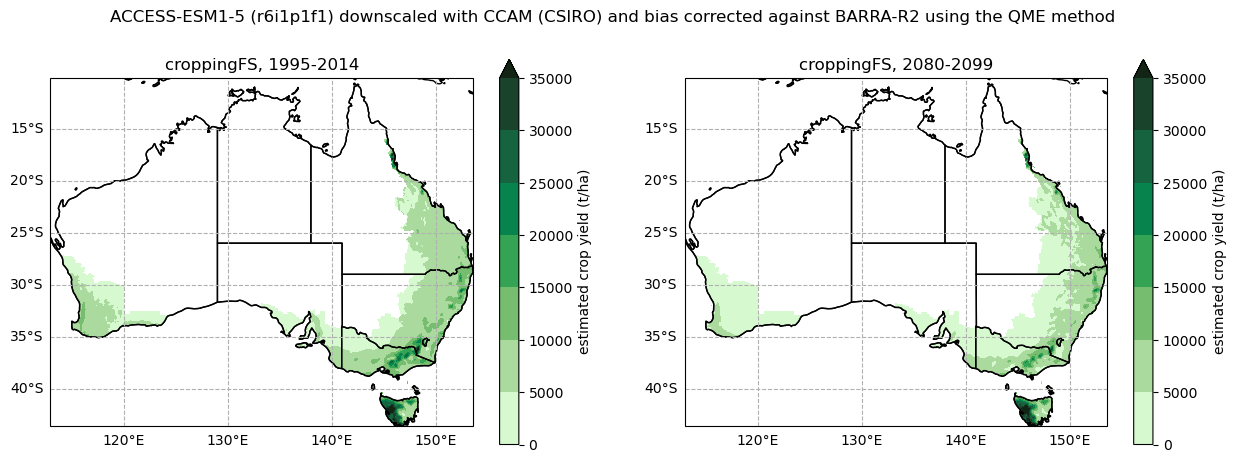

In [7]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(121, projection=ccrs.PlateCarree())
da_baseline_clim.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=np.arange(0, 40000, 5000),
    extend='max',
    cmap=cmocean.cm.algae,
    cbar_kwargs={'label': 'estimated crop yield (t/ha)'},
)
ax1.coastlines()
ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_title('croppingFS, 1995-2014')

ax2 = fig.add_subplot(122, projection=ccrs.PlateCarree())
da_future_clim.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    levels=np.arange(0, 40000, 5000),
    extend='max',
    cmap=cmocean.cm.algae,
    cbar_kwargs={'label': 'estimated crop yield (t/ha)'},
)
ax2.coastlines()
ax2.add_feature(cartopy.feature.STATES)
gls2 = ax2.gridlines(linestyle="--", draw_labels=True)
gls2.top_labels = False
gls2.right_labels = False
ax2.tick_params(axis='y', labelleft=False)
ax2.set_title('croppingFS, 2080-2099')

plt.suptitle('ACCESS-ESM1-5 (r6i1p1f1) downscaled with CCAM (CSIRO) and bias corrected against BARRA-R2 using the QME method')

plt.savefig('figures/a-e5_ccam-2203_q-barra_croppingFS_values.png', bbox_inches='tight', facecolor='white', dpi=300)
plt.show()

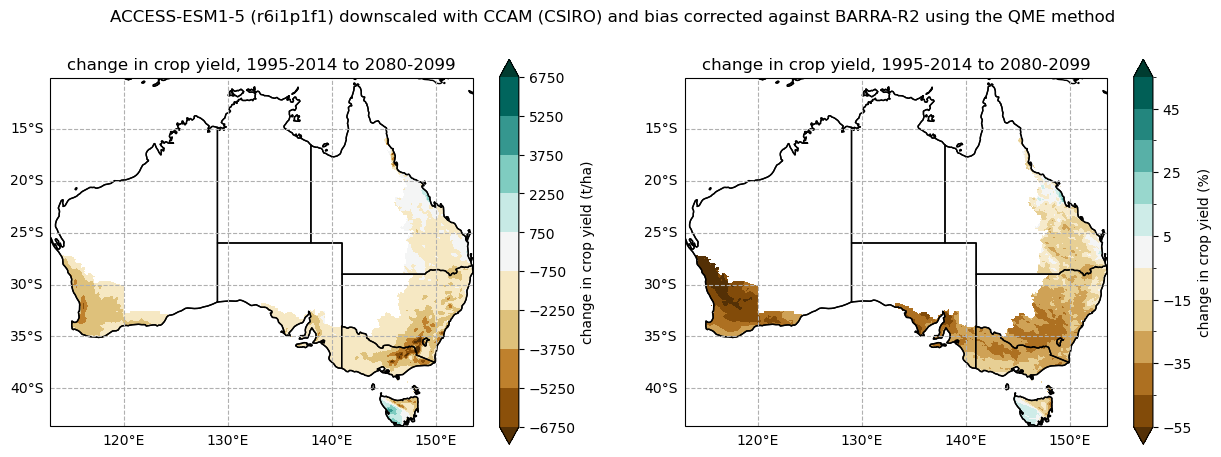

In [8]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(121, projection=ccrs.PlateCarree())
da_change.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=[-6750, -5250, -3750, -2250, -750, 750, 2250, 3750, 5250, 6750],
    extend='both',
    cmap='BrBG',
    cbar_kwargs={'label': 'change in crop yield (t/ha)'},
)
ax1.coastlines()
ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_title('change in crop yield, 1995-2014 to 2080-2099')

ax2 = fig.add_subplot(122, projection=ccrs.PlateCarree())
da_change_pct.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    levels=[-55, -45, -35, -25, -15, -5, 5, 15, 25, 35, 45, 55],
    extend='both',
    cmap='BrBG',
    cbar_kwargs={'label': 'change in crop yield (%)'},
)
ax2.coastlines()
ax2.add_feature(cartopy.feature.STATES)
gls2 = ax2.gridlines(linestyle="--", draw_labels=True)
gls2.top_labels = False
gls2.right_labels = False
ax2.tick_params(axis='y', labelleft=False)
ax2.set_title('change in crop yield, 1995-2014 to 2080-2099')

plt.suptitle('ACCESS-ESM1-5 (r6i1p1f1) downscaled with CCAM (CSIRO) and bias corrected against BARRA-R2 using the QME method')
plt.savefig('figures/a-e5_ccam-2203_q-barra_croppingFS_change.png', bbox_inches='tight', facecolor='white', dpi=300)
plt.show()

### THItropical

In [9]:
north_region = definitions.get_ncra_region('mod_ncra_nth')

In [10]:
infile_baseline = '98_2025-may_cdx_cs_a-e5_h_ccam-2203_q-barra_THItropical.csv'
da_baseline = utils.read_metric_data(infile_baseline)
da_baseline = utils.select_region(da_baseline, north_region)
da_baseline_clim = da_baseline.sel(time=slice('1995-01-01', '2014-12-31')).mean('time', keep_attrs=True)

In [11]:
infile_future = '106_2025-may_cdx_cs_a-e5_s370_ccam-2203_q-barra_THItropical.csv'
da_future = utils.read_metric_data(infile_future)
da_future = utils.select_region(da_future, north_region)
da_future_clim = da_future.sel(time=slice('2080-01-01', '2099-12-31')).mean('time', keep_attrs=True)

In [12]:
da_change = da_future_clim - da_baseline_clim

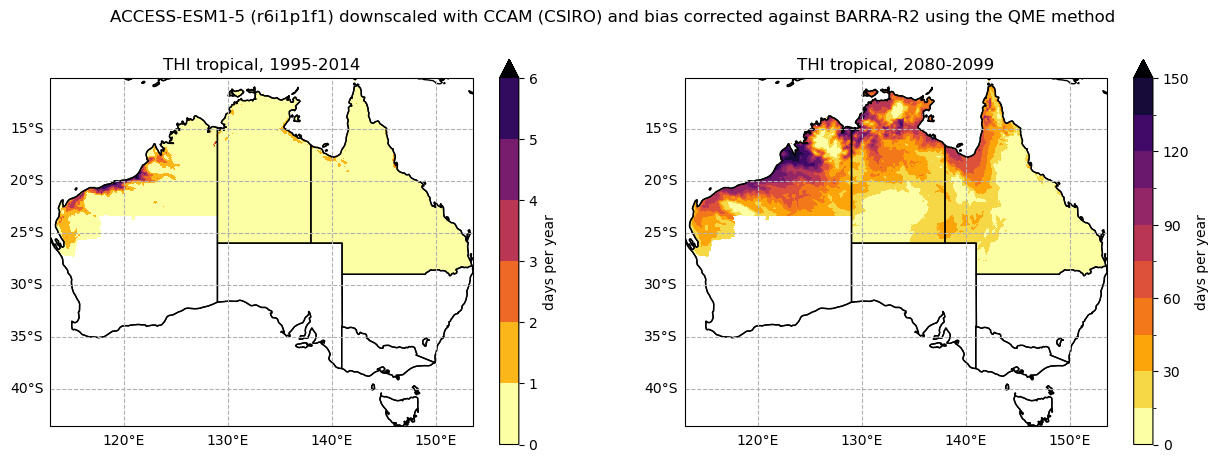

In [13]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(121, projection=ccrs.PlateCarree())
da_baseline_clim.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=[0, 1, 2, 3, 4, 5, 6],
    extend='max',
    cmap='inferno_r',
    cbar_kwargs={'label': 'days per year'},
)
ax1.coastlines()
ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_title('THI tropical, 1995-2014')

ax2 = fig.add_subplot(122, projection=ccrs.PlateCarree())
da_future_clim.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    levels=np.arange(0, 151, 15),
    extend='max',
    cmap='inferno_r',
    cbar_kwargs={'label': 'days per year'},
)
ax2.coastlines()
ax2.add_feature(cartopy.feature.STATES)
gls2 = ax2.gridlines(linestyle="--", draw_labels=True)
gls2.top_labels = False
gls2.right_labels = False
ax2.tick_params(axis='y', labelleft=False)
ax2.set_title('THI tropical, 2080-2099')

plt.suptitle('ACCESS-ESM1-5 (r6i1p1f1) downscaled with CCAM (CSIRO) and bias corrected against BARRA-R2 using the QME method')
plt.savefig('figures/a-e5_ccam-2203_q-barra_THItropical_values.png', bbox_inches='tight', facecolor='white', dpi=300)
plt.show()

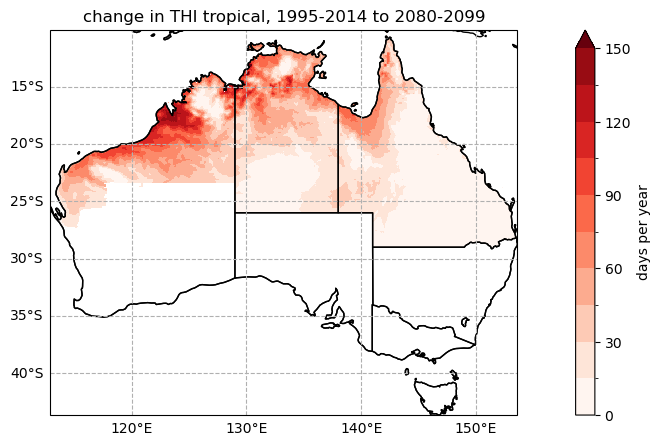

In [14]:
fig = plt.figure(figsize=[15, 5])

ax1 = fig.add_subplot(111, projection=ccrs.PlateCarree())
da_change.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    levels=np.arange(0, 151, 15),
    extend='max',
    cmap='Reds',
    cbar_kwargs={'label': 'days per year'},
)
ax1.coastlines()
ax1.add_feature(cartopy.feature.STATES)
gls1 = ax1.gridlines(linestyle="--", draw_labels=True)
gls1.top_labels = False
gls1.right_labels = False
ax1.tick_params(axis='y', labelleft=False)
ax1.set_title('change in THI tropical, 1995-2014 to 2080-2099')

#plt.suptitle('ACCESS-ESM1-5 (r6i1p1f1) downscaled with CCAM (CSIRO) bias corrected against BARRA-R2 using the QME method')
plt.show()

In [36]:
#    levels=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5],
#ax.set_extent([113, 154, -38, -21], crs=ccrs.PlateCarree())
#ax.add_geometries(
#    cropping_gdf.geometry, ccrs.PlateCarree(), facecolor="none", edgecolor="orange"
#)

In [19]:
#df_spatial_mean = da_spatial_mean.to_pandas()
#df_spatial_mean.index = df_spatial_mean.index.year
#df_spatial_mean.plot.bar(figsize=[10, 5], width=0.8)
#plt.ylabel('mm')
#plt.xlabel('year')
#plt.title('Total annual rainfall - wheatbelt average')
#plt.grid(axis='y')
#plt.show()

# Spatial aggregates

Target: Plot like Figure 7 in [Narsey et al (2025)](https://connectsci.au/es/article/75/3/ES25015/252075/Disentangling-the-uncertainties-in-regional).

In [11]:
tab20 = plt.cm.tab20.colors

marker_dict = {
    'ACCESS-CM2_r2i1p1f1': (tab20[0], 'v'),
    'ACCESS-CM2_r4i1p1f1': (tab20[0], 'o'),
    'ACCESS-ESM1-5_r6i1p1f1': (tab20[1], 'o'),
    'ACCESS-ESM1-5_r20i1p1f1': (tab20[1], 'v'),
    'ACCESS-ESM1-5_r40i1p1f1': (tab20[1], '^'),
    'CESM2_r11i1p1f1': (tab20[2], 'o'),
    'CMCC-ESM2_r1i1p1f1': (tab20[3], 'o'),
    'CNRM-CM6-1-HR_r1i1p1f2': (tab20[4], 'o'),
    'CNRM-ESM2-1_r1i1p1f2': (tab20[5], 'o'),
    'EC-Earth3_r1i1p1f1': (tab20[6], 'o'),
    'EC-Earth3-Veg_r1i1p1f1': (tab20[7], 'o'),
    'FGOALS-g3_r4i1p1f1': (tab20[8], 'o'),
    'GFDL-ESM4_r1i1p1f1': (tab20[9], 'o'),
    'GISS-E2-1-G_r2i1p1f2': (tab20[10], 'o'),
    'MPI-ESM1-2-HR_r1i1p1f1': (tab20[12], 'o'),
    'MPI-ESM1-2-LR_r9i1p1f1': (tab20[13], 'o'),
    'MRI-ESM2-0_r1i1p1f1': (tab20[14], 'o'),
    'NorESM2-MM_r1i1p1f1': (tab20[15], 'o'),
    'UKESM1-0-LL_r1i1p1f2': (tab20[16], 'o'),
}

In [12]:
def metric_raw(infile, metric, bc, exp):
    """Process a metric file"""
    
    ds = xr.open_dataset(infile)
    
    da_baseline = ds[metric].sel(time=slice('1995-01-01', '2014-12-31')).mean('time', keep_attrs=True)
    if 'qdc' in infile:
        if 'AGCD' in bc:
            da_baseline = da_baseline.sel({'experiment': exp, 'obs': 'AGCD'})
        elif 'BARRA' in bc:
            da_baseline = da_baseline.sel({'experiment': exp, 'obs': 'BARRA-R2'})
    else:
        da_baseline = da_baseline.sel({'experiment': exp, 'bc': bc})
    
    da_future = ds[metric].sel(time=slice('2080-01-01', '2099-12-31')).mean('time', keep_attrs=True)
    if 'qdc' in infile:
        if 'AGCD' in bc:
            da_future = da_future.sel({'experiment': exp, 'obs': 'AGCD'})
        elif 'BARRA' in bc:
            da_future = da_future.sel({'experiment': exp, 'obs': 'BARRA-R2'})
    else:
        da_future = da_future.sel({'experiment': exp, 'bc': bc})
    
    return da_baseline, da_future


def metric_change(infile, metric, bc, exp, pct=False):
    """Process a metric file"""
    
    da_baseline, da_future = metric_raw(infile, metric, bc, exp)
    da_change = da_future - da_baseline
    if pct:
        da_change = (da_change / da_baseline) * 100
    
    return da_change

In [13]:
units_dict = {
    'THItropical': 'days per year',
    'croppingFS': 't/ha'
}

In [14]:
def plot_values(metric, region, bc, exp, ylim=[], savefig=False):
    """Plot values"""

    ensfile = {
        f'data/{metric}_bar_{region}.nc': 1,
        f'data/{metric}_ccam-2203_{region}.nc': 2,
        f'data/{metric}_nar-r3_{region}.nc': 2.9,
        f'data/{metric}_nar-r5_{region}.nc': 3.1,
        f'data/{metric}_ccam-2105_{region}.nc': 4,
        f'data/{metric}_ccam-2105-r6_{region}.nc': 4,
        f'data/{metric}_ccam-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r2_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r4_{region}.nc': 4,
        f'data/{metric}_qdc_{region}.nc': 5,
    } 

    fig = plt.figure(figsize=(10, 5))
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)
    
    label_list = []
    baseline_values_dict = {1: [], 2: [], 2.9: [], 3.1: [], 4: [], 5: []}
    future_values_dict = {1: [], 2: [], 2.9: [], 3.1: [], 4: [], 5: []}
    for infile, index in ensfile.items():
        da_baseline, da_future = metric_raw(infile, metric, bc, exp)
        for gcm in da_baseline['gcm'].values:
            baseline_value = float(da_baseline.sel({'gcm': gcm}).values)
            future_value = float(da_future.sel({'gcm': gcm}).values)
            if math.isnan(baseline_value) or math.isnan(future_value):
                continue
            color, marker = marker_dict[gcm]
            label = gcm.replace('_' , ' ') if not gcm in label_list else None
            label_list.append(gcm)
            jitter = random.uniform(-0.05, 0.05)
            ax1.plot(index + jitter, baseline_value, marker=marker, color=color, label=label, linestyle='none')
            ax2.plot(index + jitter, future_value, marker=marker, color=color, label=label, linestyle='none')
            baseline_values_dict[index].append(baseline_value)
            future_values_dict[index].append(future_value)
    
    for index in list(set(list(ensfile.values()))):
        inst_min = np.nanmin(np.array(baseline_values_dict[index]))
        inst_max = np.nanmax(np.array(baseline_values_dict[index]))
        ax1.plot([index, index], [inst_min, inst_max], color='black', linewidth=0.5, marker='_', zorder=0)
    
    for index in list(set(list(ensfile.values()))):
        inst_min = np.nanmin(np.array(future_values_dict[index]))
        inst_max = np.nanmax(np.array(future_values_dict[index]))
        ax2.plot([index, index], [inst_min, inst_max], color='black', linewidth=0.5, marker='_', zorder=0)
    
    handles, labels = ax2.get_legend_handles_labels()
    labels, handles = zip(*sorted(zip(labels, handles), key=lambda t: t[0]))
    ax2.legend(handles, labels, bbox_to_anchor=(1.8, 0.5), loc=7)
    units = units_dict[metric]
    ax1.set_ylabel(units)
    ax2.set_ylabel(units)
    ax1.set_xticks([1, 2, 3, 4, 5], labels=['BOM', 'CSIRO', 'NSW Gov', 'UQ-DEC', 'QDC'])
    ax2.set_xticks([1, 2, 3, 4, 5], labels=['BOM', 'CSIRO', 'NSW Gov', 'UQ-DEC', 'QDC'])
    ax1.set_title(f'{metric}, 1995-2014 (ssp370)')
    ax2.set_title(f'{metric}, 2080-2099 (ssp370)')
    if ylim:
        ax1.set_ylim(ylim)
        ax2.set_ylim(ylim)
    
    if savefig:
        outfile = f'{metric}-values_{region}_{bc}_{exp}.png'
        plt.savefig(outfile, bbox_inches='tight', facecolor='white', dpi=300)
        print(outfile)
    plt.show()

In [15]:
def plot_change(metric, region, bc, exp, pct=False, savefig=False):
    """Plot change"""

    ensfile = {
        f'data/{metric}_bar_{region}.nc': 1,
        f'data/{metric}_ccam-2203_{region}.nc': 2,
        f'data/{metric}_nar-r3_{region}.nc': 2.9,
        f'data/{metric}_nar-r5_{region}.nc': 3.1,
        f'data/{metric}_ccam-2105_{region}.nc': 4,
        f'data/{metric}_ccam-2105-r6_{region}.nc': 4,
        f'data/{metric}_ccam-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r2_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r4_{region}.nc': 4,
        f'data/{metric}_qdc_{region}.nc': 5,
    } 
    
    fig = plt.figure(figsize=(5, 5))
    ax1 = plt.subplot(111)
    
    label_list = []
    change_values_dict = {1: [], 2: [], 2.9: [], 3.1: [], 4: [], 5: []}
    for infile, index in ensfile.items():
        da_change = metric_change(infile, metric, bc, exp, pct=pct)
        for gcm in da_change['gcm'].values:
            change_value = float(da_change.sel({'gcm': gcm}).values)
            if math.isnan(change_value):
                continue
            color, marker = marker_dict[gcm]
            label = gcm.replace('_' , ' ') if not gcm in label_list else None
            label_list.append(gcm)
            jitter = random.uniform(-0.05, 0.05)
            ax1.plot(index + jitter, change_value, marker=marker, color=color, label=label, linestyle='none')
            change_values_dict[index].append(change_value)
    
    for index in list(set(list(ensfile.values()))):
        inst_min = np.nanmin(np.array(change_values_dict[index]))
        inst_max = np.nanmax(np.array(change_values_dict[index]))
        ax1.plot([index, index], [inst_min, inst_max], color='black', linewidth=0.5, marker='_', zorder=0)
    
    handles, labels = ax1.get_legend_handles_labels()
    labels, handles = zip(*sorted(zip(labels, handles), key=lambda t: t[0]))
    ax1.legend(handles, labels, bbox_to_anchor=(1.7, 0.5), loc=7)
    units = '%' if pct else units_dict[metric]
    ax1.set_ylabel(units)
    ax1.axhline(y=0, linestyle=':', color='0.5')
    ax1.set_xticks([1, 2, 3, 4, 5], labels=['BOM', 'CSIRO', 'NSW Gov', 'UQ-DEC', 'QDC'])
    ax1.set_title(f'Change in {metric}, 1995-2014 to 2080-2099 ({exp})')

    if savefig:
        end = '_pct.png' if pct else '.png'
        outfile = f'{metric}-change_{region}_{bc}_{exp}{end}'
        plt.savefig(outfile, bbox_inches='tight', facecolor='white', dpi=300)
        print(outfile)
    plt.show()

THItropical-values_mod-ncra-nth_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370.png


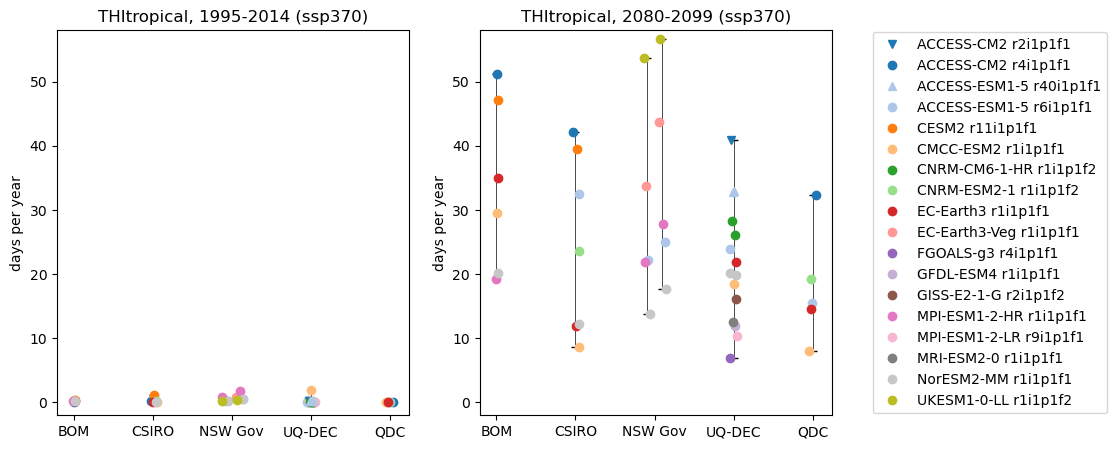

In [16]:
plot_values('THItropical', 'mod-ncra-nth', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', ylim=[-2, 58], savefig=True)

THItropical-change_mod-ncra-nth_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370.png


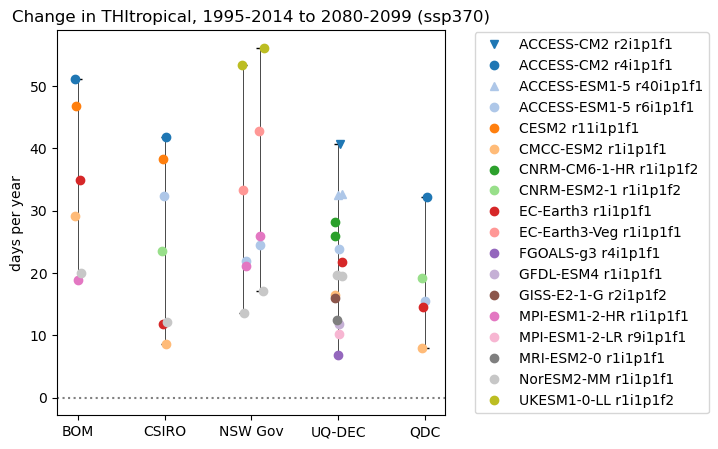

In [17]:
plot_change('THItropical', 'mod-ncra-nth', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', savefig=True)

croppingFS-values_cropping_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370.png


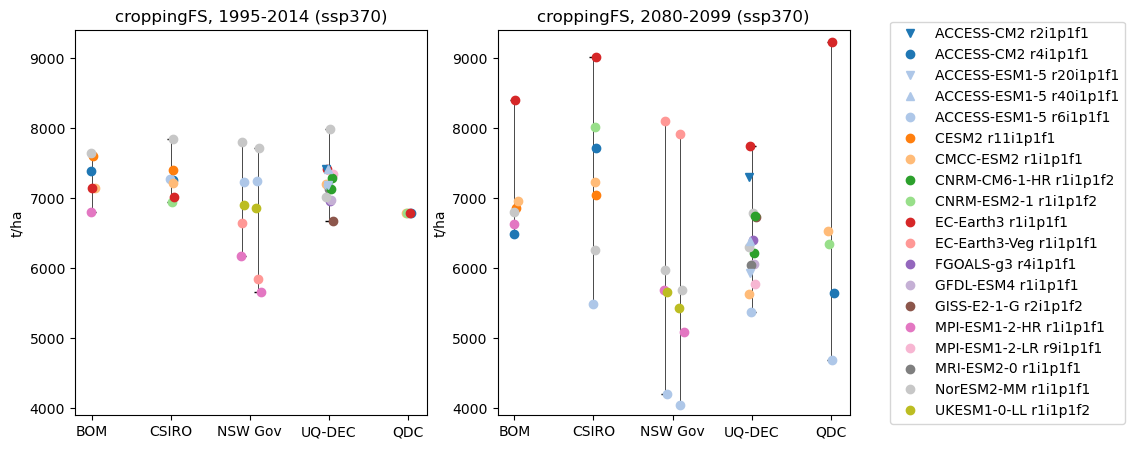

In [18]:
plot_values('croppingFS', 'cropping', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', ylim=[3900, 9400], savefig=True)

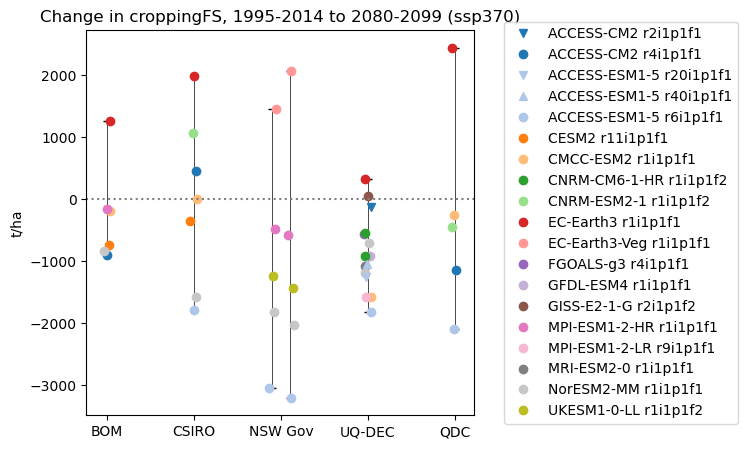

In [19]:
plot_change('croppingFS', 'cropping', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', pct=False, savefig=False)

croppingFS-change_cropping_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370_pct.png


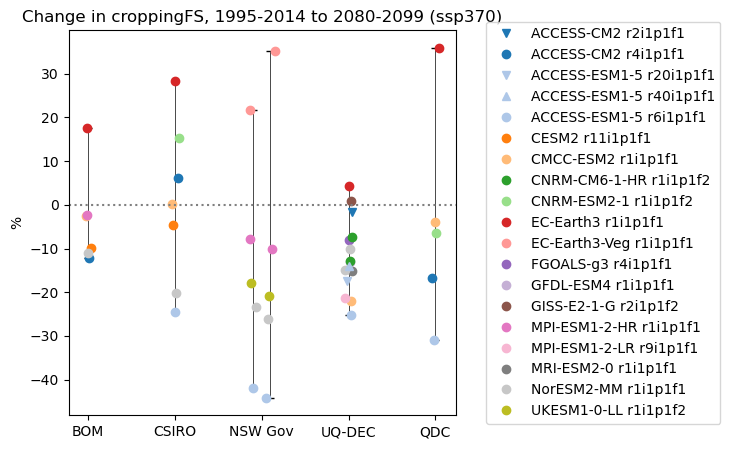

In [20]:
plot_change('croppingFS', 'cropping', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', pct=True, savefig=True)